# Exploratory analysis

This first pass covers D2 (Jigsaw) and our Dating Stress Test. D1 is next: run `load_toxic_conversations()` and rerun these cells with it.

The notebook shows counts and charts, and no raw comments, because the data contains offensive language.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from red_flag_detector import deduplicate, load_jigsaw, load_stress_test
from red_flag_detector.data import JIGSAW_TYPES
from red_flag_detector.plots import AQUA, BLUE, MUTED, ORANGE, apply_style, save

apply_style()
root = Path.cwd().parent
results = root / "results"
jigsaw = load_jigsaw(root / "data" / "raw" / "jigsaw_train.csv")
stress = load_stress_test(root / "data" / "dating_stress_test.csv")

## Size, missing values and duplicates

In [2]:
unique = deduplicate(jigsaw)
overview = pd.Series({
    "rows": len(jigsaw),
    "missing text": int(jigsaw["text"].eq("").sum()),
    "toxic rows": int(jigsaw["label"].sum()),
    "toxic share": round(jigsaw["label"].mean(), 4),
    "rows removed by deduplication": len(jigsaw) - len(unique),
    "toxic share after deduplication": round(unique["label"].mean(), 4),
})
overview

rows                               159571.0000
missing text                            0.0000
toxic rows                          16225.0000
toxic share                             0.1017
rows removed by deduplication         271.0000
toxic share after deduplication         0.1015
dtype: float64

## Class balance

About one comment in ten is toxic, so a model that always says "not toxic" reaches about 90% accuracy and finds nothing. We report F1 for the toxic class.

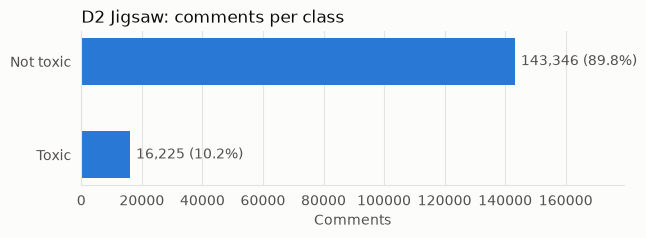

In [3]:
counts = jigsaw["label"].value_counts().rename({0: "Not toxic", 1: "Toxic"}).sort_values()
fig, ax = plt.subplots(figsize=(7, 2))
bars = ax.barh(counts.index, counts.values, color=BLUE, height=0.5)
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.1%})" for v in counts.values], padding=4, color=MUTED)
ax.set_title("D2 Jigsaw: comments per class")
ax.set_xlabel("Comments")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.25)
save(fig, results / "class_distribution.png")

## Toxicity types

D2 adds the types that D1 lacks. Threats are rare, so a model has few examples of the type a dating user would care about most.

threat             478
identity_hate     1405
severe_toxic      1595
insult            7877
obscene           8449
toxic            15294
dtype: int64

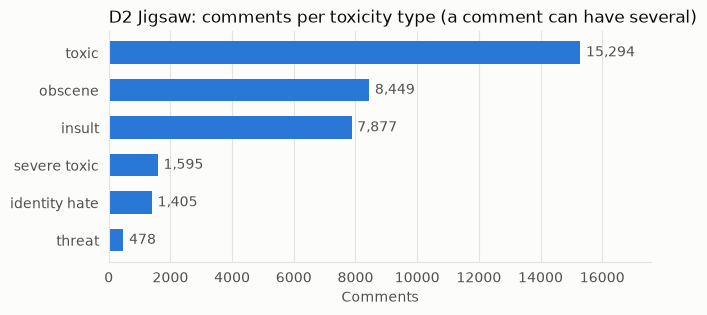

In [4]:
types = jigsaw[JIGSAW_TYPES].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh([t.replace("_", " ") for t in types.index], types.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in types.values], padding=4, color=MUTED)
ax.set_title("D2 Jigsaw: comments per toxicity type (a comment can have several)")
ax.set_xlabel("Comments")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, types.max() * 1.15)
save(fig, results / "toxicity_types.png")
types

## Message length: the first sign of a domain gap

Dating messages run far shorter than training comments, so a model sees less evidence per message at test time. One caution: we wrote these test messages ourselves, so real chats may differ. We should check the gap on real chat data if we find any.

,D2 not toxic,D2 toxic,Dating Stress Test
count,143346.0,16225.0,120.0
mean,68.9,52.7,9.4
std,98.2,106.9,1.9
min,1.0,2.0,4.0
50%,38.0,23.0,9.0
95%,235.0,176.0,13.0
max,1250.0,1411.0,15.0


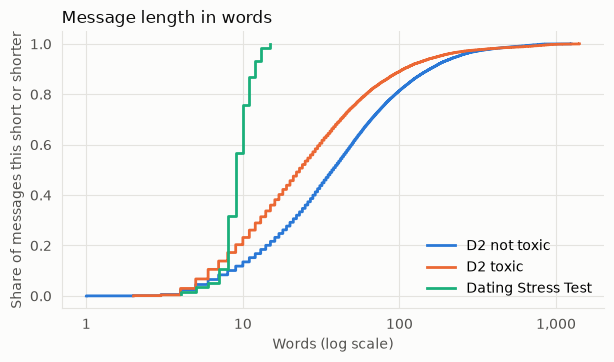

In [5]:
def words(texts):
    return texts.str.split().str.len().to_numpy()

groups = {
    "D2 not toxic": (words(jigsaw.loc[jigsaw["label"] == 0, "text"]), BLUE),
    "D2 toxic": (words(jigsaw.loc[jigsaw["label"] == 1, "text"]), ORANGE),
    "Dating Stress Test": (words(stress["text"]), AQUA),
}
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, (lengths, colour) in groups.items():
    values = np.sort(lengths)
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=colour, linewidth=2, label=name)
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax.set_title("Message length in words")
ax.set_xlabel("Words (log scale)")
ax.set_ylabel("Share of messages this short or shorter")
ax.legend(frameon=False, loc="lower right")
save(fig, results / "message_length.png")
pd.DataFrame({name: pd.Series(lengths).describe(percentiles=[0.5, 0.95]) for name, (lengths, _) in groups.items()}).round(1)

## Dating Stress Test

In [6]:
stress.groupby(["scope", "category"]).agg(messages=("id", "size"), label=("label", "first"))

messages  label
scope   category                           
core    explicit_insult           10      1
        friendly_flirt            10      0
        healthy_conflict          10      0
        identity_mention          10      0
        neutral_logistics         10      0
        playful_banter            10      0
        polite_rejection          10      0
        put_down                  10      1
        threat                    10      1
stretch gaslighting               10      1
        guilt_manipulation        10      1
        sexual_pressure           10      1